<a href="https://colab.research.google.com/github/Wilkelson/A01724709-Repository/blob/main/Actividad_5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

['folio', 'intp', 'entidad', 'desc_ent', 'sexo', 'edad', 'meses', 'peso', 'ropa', 'talla', 'emb', 'temb', 'cintura', 'cadera', 'sistol', 'diastol', 'hpresion', 'tbrazo', 'htension', 'PrimaryLast', 'code_upm', 'est_dis', 'est_urb', 'est_marg', 'pondef', 'est_var']
folio            int64
intp             int64
entidad          int64
desc_ent        object
sexo             int64
edad             int64
meses            int64
peso           float64
ropa             int64
talla          float64
emb             object
temb            object
cintura        float64
cadera         float64
sistol         float64
diastol        float64
hpresion        object
tbrazo          object
htension        object
PrimaryLast      int64
code_upm        object
est_dis          int64
est_urb          int64
est_marg         int64
pondef         float64
est_var          int64
dtype: object


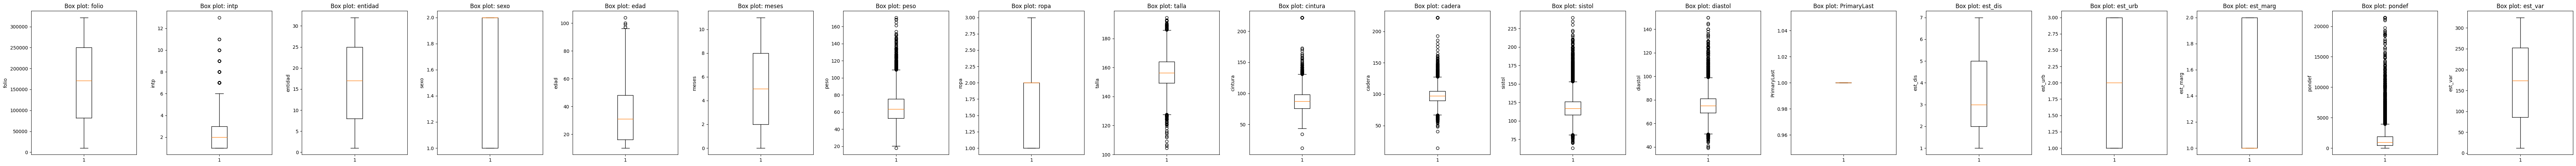

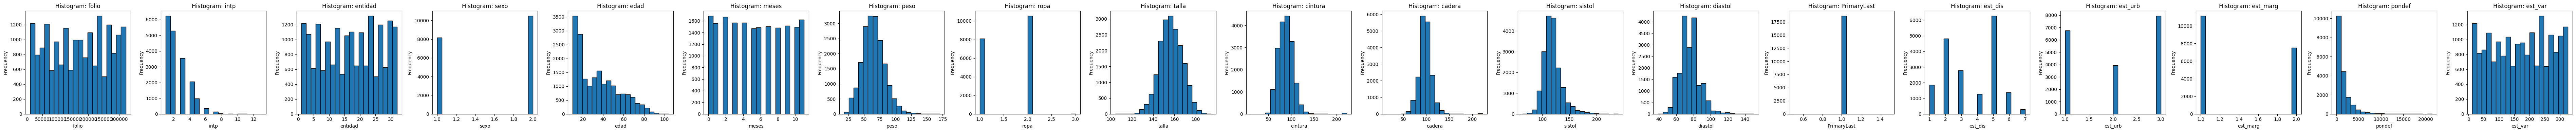

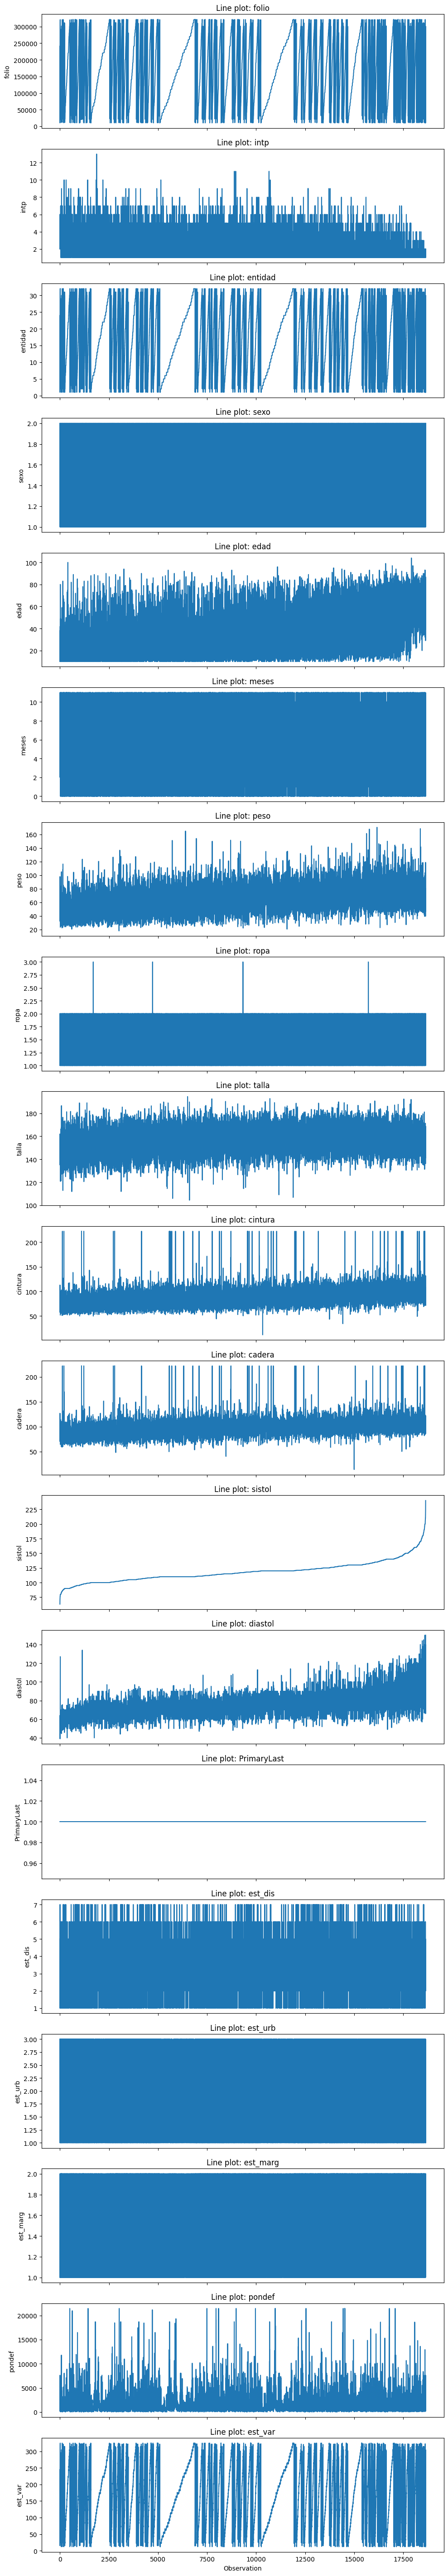

In [2]:

import matplotlib.pyplot as plt



print(df.columns.tolist())
print(df.dtypes)

variables = df.select_dtypes(include='number').columns.tolist()
n = len(variables)

fig, axes = plt.subplots(1, n, figsize=(4 * n, 5))
axes = [axes] if n == 1 else axes
for ax, col in zip(axes, variables):
    ax.boxplot(df[col].dropna())
    ax.set_title(f'Box plot: {col}')
    ax.set_ylabel(col)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, n, figsize=(4 * n, 4))
axes = [axes] if n == 1 else axes
for ax, col in zip(axes, variables):
    ax.hist(df[col].dropna(), bins=20, edgecolor='black')
    ax.set_title(f'Histogram: {col}')
    ax.set_xlabel(col)
    ax.set_ylabel('Frequency')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(n, 1, figsize=(10, 3 * n), sharex=True)
axes = [axes] if n == 1 else axes

for ax, col in zip(axes, variables):
    ax.plot(df.index, df[col])
    ax.set_ylabel(col)
    ax.set_title(f'Line plot: {col}')
axes[-1].set_xlabel('Observation')
plt.tight_layout()
plt.show()

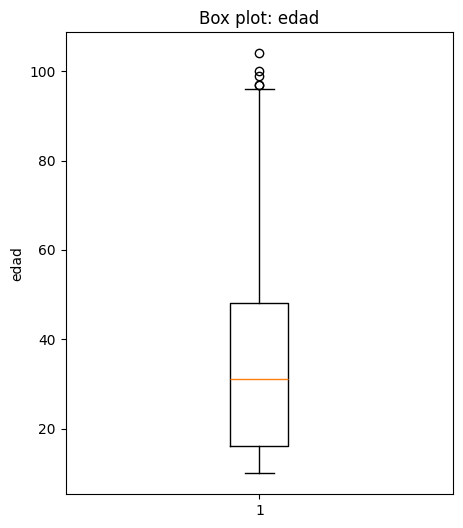

In [3]:


plt.figure(figsize=(5, 6))
plt.boxplot(df['edad'].dropna())
plt.title('Box plot: edad')
plt.ylabel('edad')
plt.show()

In [11]:
tabla = df.pivot_table(index='entidad', columns='sexo', values='peso', aggfunc='median', margins=True)
tabla.index.name = 'index'
tabla

sexo,1,2,All
index,,,
1,69.9500,63.7000,66.6000
2,70.6500,64.2000,67.9500
3,76.6500,68.5500,71.2500
4,67.3500,62.3750,64.3500
5,68.3000,67.3000,67.7000
6,71.7000,66.0000,68.9000
7,59.2000,56.0250,57.2000
8,69.3000,64.6250,66.3000
9,69.0000,61.4500,64.0250


62.0


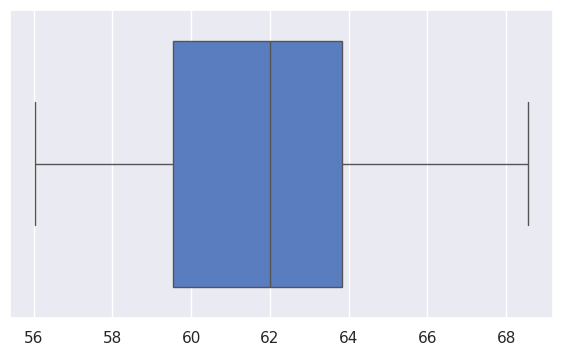

In [12]:
medianas_sexo2 = tabla[2].drop('All')

print(medianas_sexo2.median())

plt.figure(figsize=(7, 4))
sns.boxplot(x=medianas_sexo2, color=sns.color_palette('muted')[0], showfliers=False)
plt.xlabel('')
plt.show()

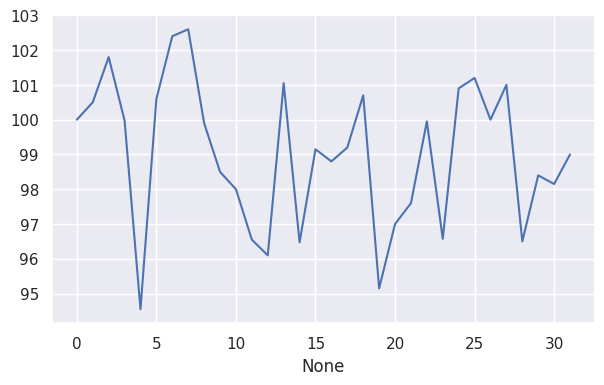

In [15]:
sns.set_theme(style='darkgrid')

tabla_cadera = df.pivot_table(index='desc_ent', columns='sexo', values='cadera', aggfunc='median', margins=True)

cadera_sexo2 = tabla_cadera[2].drop('All').reset_index(drop=True)

plt.figure(figsize=(7, 4))
sns.lineplot(x=cadera_sexo2.index, y=cadera_sexo2.values)
plt.show()

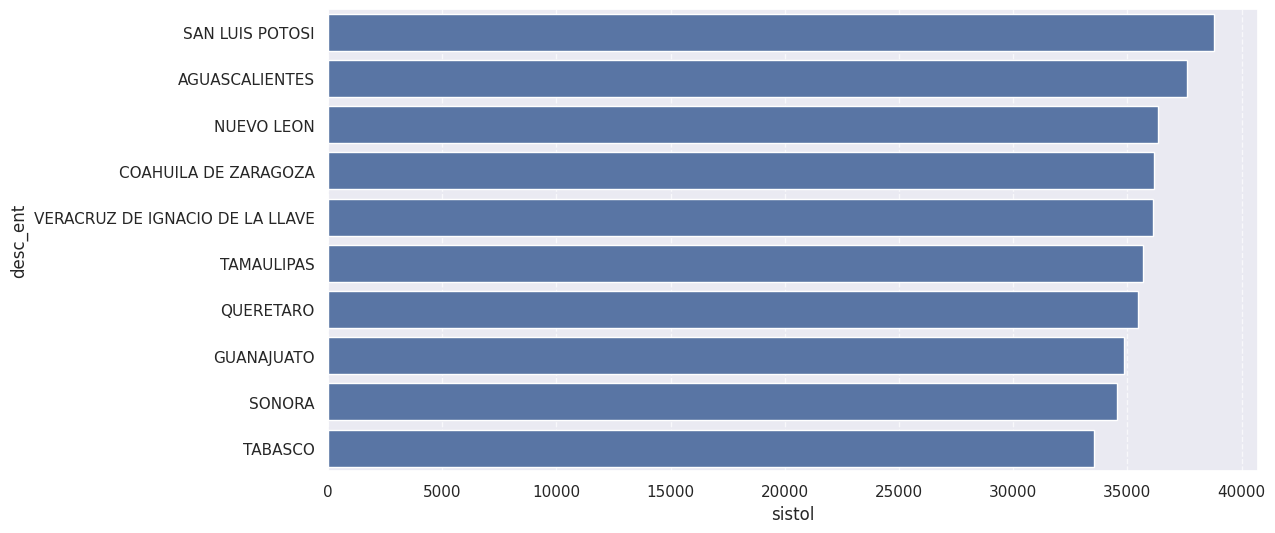

In [19]:
top_states = df[df['sexo'] == 1].groupby('desc_ent')['sistol'].sum().reset_index()
top_10_states = top_states.sort_values(by='sistol', ascending=False).head(10)

plt.figure(figsize=(12, 6))
sns.barplot(
    data=top_10_states,
    x='sistol',
    y='desc_ent',


    legend=False
)
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()

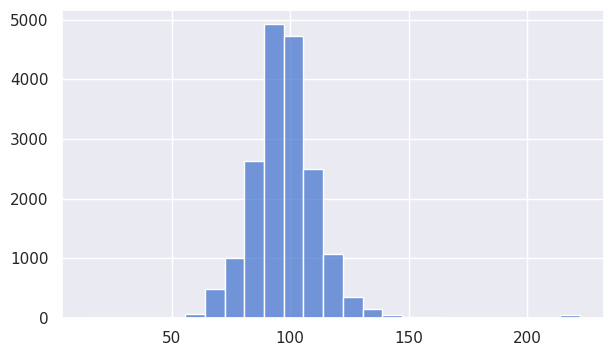

In [18]:
sns.set_theme(style='darkgrid')

plt.figure(figsize=(7, 4))
sns.histplot(df['cadera'].dropna(), bins=25, color=sns.color_palette('muted')[0])
plt.xlabel('')
plt.ylabel('')
plt.show()